In [ ]:
# import library & lokasi file hasil
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
from collections import Counter

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE = "/content/drive/MyDrive/ml-semester5/KUIS-1"
DIR_KMEANS = os.path.join(BASE, "outputKmeans")
DIR_DBSCAN = os.path.join(BASE, "outputDBSCAN")
OUTPUT_DIR = os.path.join(BASE, "outputPerbandingan")
os.makedirs(OUTPUT_DIR, exist_ok=True)

FILES = [
    ('K-Means', 'Euclidean', os.path.join(DIR_KMEANS, 'evaluasi_kmeans_euclidean.xlsx')),
    ('K-Means', 'Manhattan', os.path.join(DIR_KMEANS, 'evaluasi_kmeans_manhattan.xlsx')),
    ('K-Means', 'Cosine',    os.path.join(DIR_KMEANS, 'evaluasi_kmeans_cosine.xlsx')),
    ('DBSCAN',  'Euclidean', os.path.join(DIR_DBSCAN, 'evaluasi_dbscan_euclidean.xlsx')),
    ('DBSCAN',  'Manhattan', os.path.join(DIR_DBSCAN, 'evaluasi_dbscan_manhattan.xlsx')),
    ('DBSCAN',  'Cosine',    os.path.join(DIR_DBSCAN, 'evaluasi_dbscan_cosine.xlsx')),
]

# Cek file yang sudah ada
for algo, metrik, path in FILES:
    status = "ADA" if os.path.exists(path) else "BELUM ADA"
    print(f"[{status}] {algo:8s} {metrik:10s} -> {path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[ADA] K-Means  Euclidean  -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_euclidean.xlsx
[ADA] K-Means  Manhattan  -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_manhattan.xlsx
[ADA] K-Means  Cosine     -> /content/drive/MyDrive/ml-sem5/kuis1/outputKmeans/evaluasi_kmeans_cosine.xlsx
[ADA] DBSCAN   Euclidean  -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_euclidean.xlsx
[ADA] DBSCAN   Manhattan  -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_manhattan.xlsx
[ADA] DBSCAN   Cosine     -> /content/drive/MyDrive/ml-sem5/kuis1/outputDBSCAN/evaluasi_dbscan_cosine.xlsx


In [ ]:
# baca & samakan kolom semua hasil
def ambil(df, awalan):
    # ambil nilai dari kolom yang namanya diawali teks tertentu (nama kolom tiap file sedikit berbeda)
    kolom = [c for c in df.columns if c.startswith(awalan)]
    return df[kolom[0]].iloc[0] if kolom else np.nan

rows = []
for algo, metrik, path in FILES:
    if not os.path.exists(path):
        print(f"[LEWAT] File belum ada: {path}")
        continue
    d = pd.read_excel(path, sheet_name='Ringkasan_Evaluasi')

    if algo == 'K-Means':
        n_klaster = ambil(d, 'Optimal k')
        parameter = f"k = {int(n_klaster)}"
        noise = np.nan
    else:
        n_klaster = ambil(d, 'Jumlah Klaster')
        parameter = f"eps = {ambil(d, 'eps')}, MinPts = {int(ambil(d, 'MinPts'))}"
        noise = ambil(d, 'Noise (%)')

    rows.append({
        'Algoritma': algo,
        'Metrik Jarak': metrik,
        'Parameter': parameter,
        'Jumlah Data': ambil(d, 'Jumlah Data'),
        'Jumlah Klaster': n_klaster,
        'Noise (%)': noise,
        'Silhouette (↑)': ambil(d, 'Silhouette'),
        'Davies–Bouldin (↓)': ambil(d, 'Davies'),
        'Calinski–Harabasz (↑)': ambil(d, 'Calinski'),
        'Waktu Eksekusi (s) (↓)': ambil(d, 'Execution Time'),
        'Iterasi (↓)': ambil(d, 'Iterations'),
        'Nilai Objektif': ambil(d, 'Objective Value'),
    })

perbandingan = pd.DataFrame(rows)
print(f"[INFO] {len(perbandingan)} dari {len(FILES)} hasil berhasil dibaca.")

[INFO] 6 dari 6 hasil berhasil dibaca.


In [ ]:
# tabel perbandingan per algoritma
metrik_nilai = ['Silhouette (↑)', 'Davies–Bouldin (↓)', 'Calinski–Harabasz (↑)', 'Waktu Eksekusi (s) (↓)']

kolom_tabel = {
    'K-Means': ['Metrik Jarak', 'Parameter', 'Jumlah Data', 'Jumlah Klaster',
                'Silhouette (↑)', 'Davies–Bouldin (↓)', 'Calinski–Harabasz (↑)',
                'Waktu Eksekusi (s) (↓)', 'Iterasi (↓)', 'Nilai Objektif'],
    'DBSCAN':  ['Metrik Jarak', 'Parameter', 'Jumlah Data', 'Jumlah Klaster', 'Noise (%)',
                'Silhouette (↑)', 'Davies–Bouldin (↓)', 'Calinski–Harabasz (↑)', 'Waktu Eksekusi (s) (↓)'],
}

tabel_algo = {}
for algo in ['K-Means', 'DBSCAN']:
    sub = perbandingan[perbandingan['Algoritma'] == algo][kolom_tabel[algo]].reset_index(drop=True)
    tabel_algo[algo] = sub
    print("=" * 120)
    print(f"PERBANDINGAN METRIK JARAK - {algo.upper()}")
    print("=" * 120)
    print(sub.to_string(index=False))
    print()

excel_path = os.path.join(OUTPUT_DIR, "perbandingan_per_algoritma.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    for algo, sub in tabel_algo.items():
        sub.to_excel(writer, sheet_name=algo, index=False)
    perbandingan.to_excel(writer, sheet_name='Gabungan_Pelengkap', index=False)
print(f"[SIMPAN] Tabel perbandingan disimpan ke: '{excel_path}'")

PERBANDINGAN METRIK JARAK - K-MEANS
Metrik Jarak Parameter  Jumlah Data  Jumlah Klaster  Silhouette (↑)  Davies–Bouldin (↓)  Calinski–Harabasz (↑)  Waktu Eksekusi (s) (↓)  Iterasi (↓)  Nilai Objektif
   Euclidean     k = 4        63197               4          0.1068              2.3585                7218.13                 0.62206          NaN       706021.99
   Manhattan     k = 4        63197               4          0.1259              2.9280                5124.80                 0.27095          5.0       504403.99
      Cosine     k = 4        63197               4          0.1982              2.5052                6258.32                 1.05867         23.0        32743.10

PERBANDINGAN METRIK JARAK - DBSCAN
Metrik Jarak                 Parameter  Jumlah Data  Jumlah Klaster  Noise (%)  Silhouette (↑)  Davies–Bouldin (↓)  Calinski–Harabasz (↑)  Waktu Eksekusi (s) (↓)
   Euclidean eps = 1.7321, MinPts = 30        63197             207      27.64          0.2593              1.

[SIMPAN] Grafik K-Means disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputPerbandingan/perbandingan_kmeans.png'


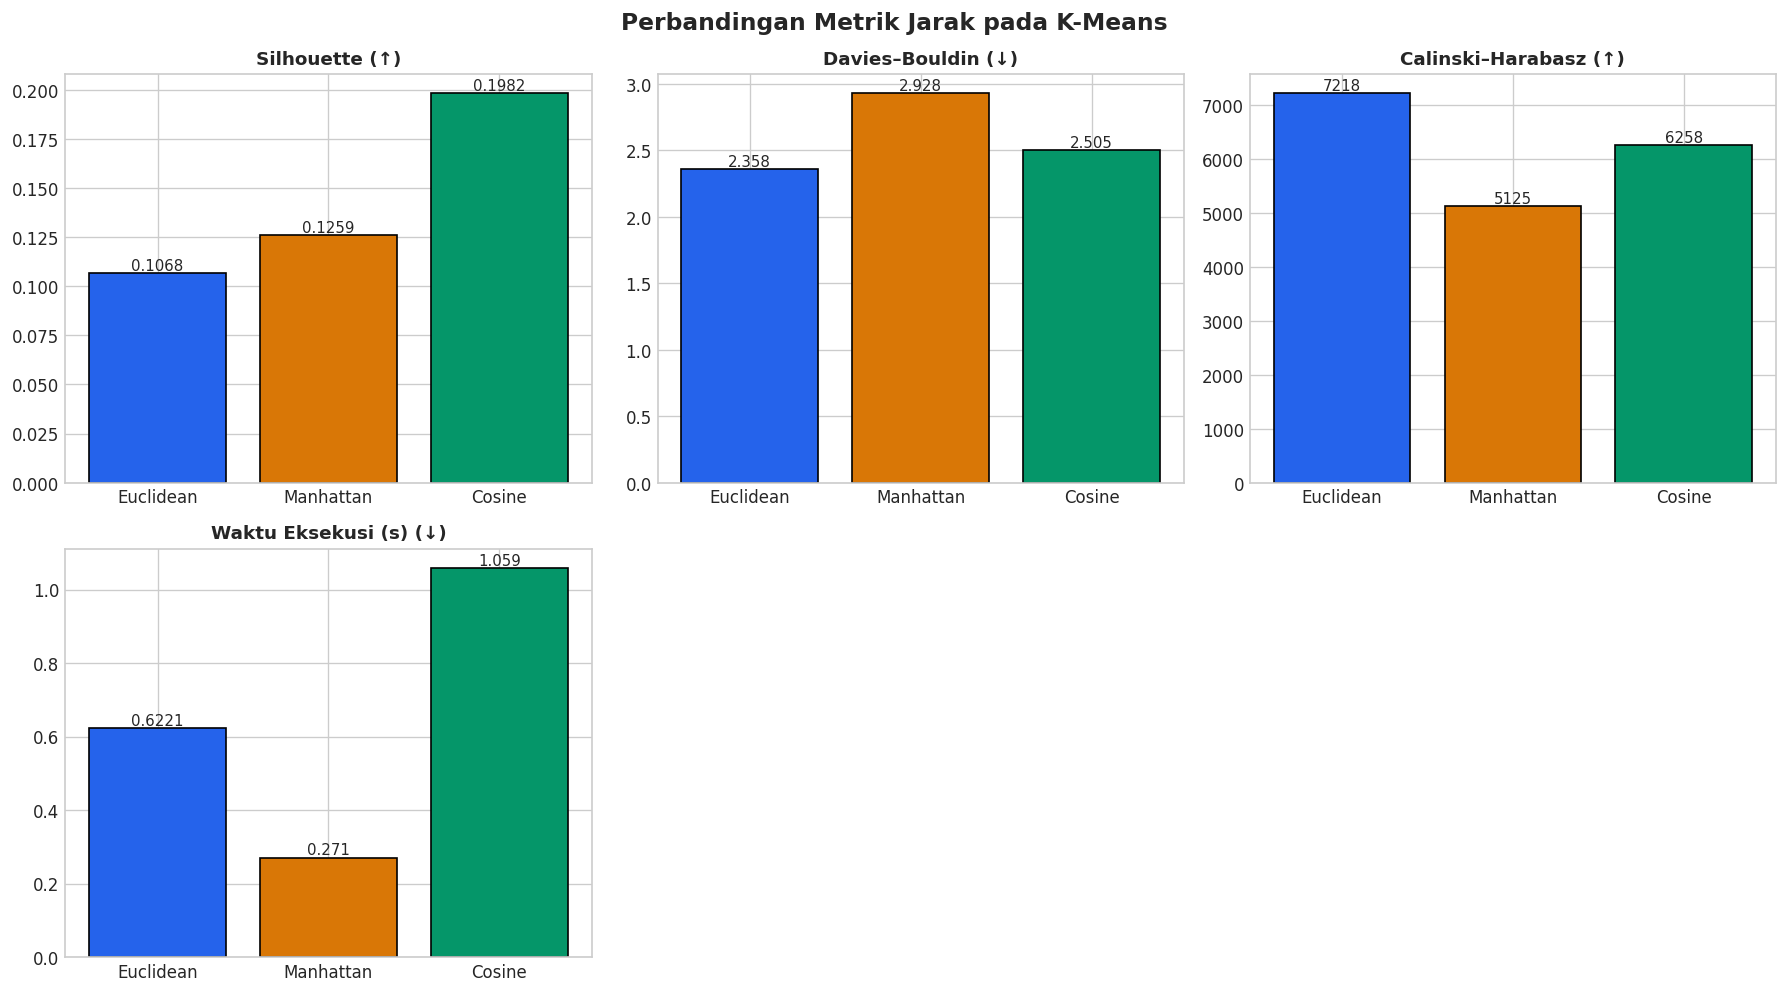

[SIMPAN] Grafik DBSCAN disimpan ke: '/content/drive/MyDrive/ml-sem5/kuis1/outputPerbandingan/perbandingan_dbscan.png'


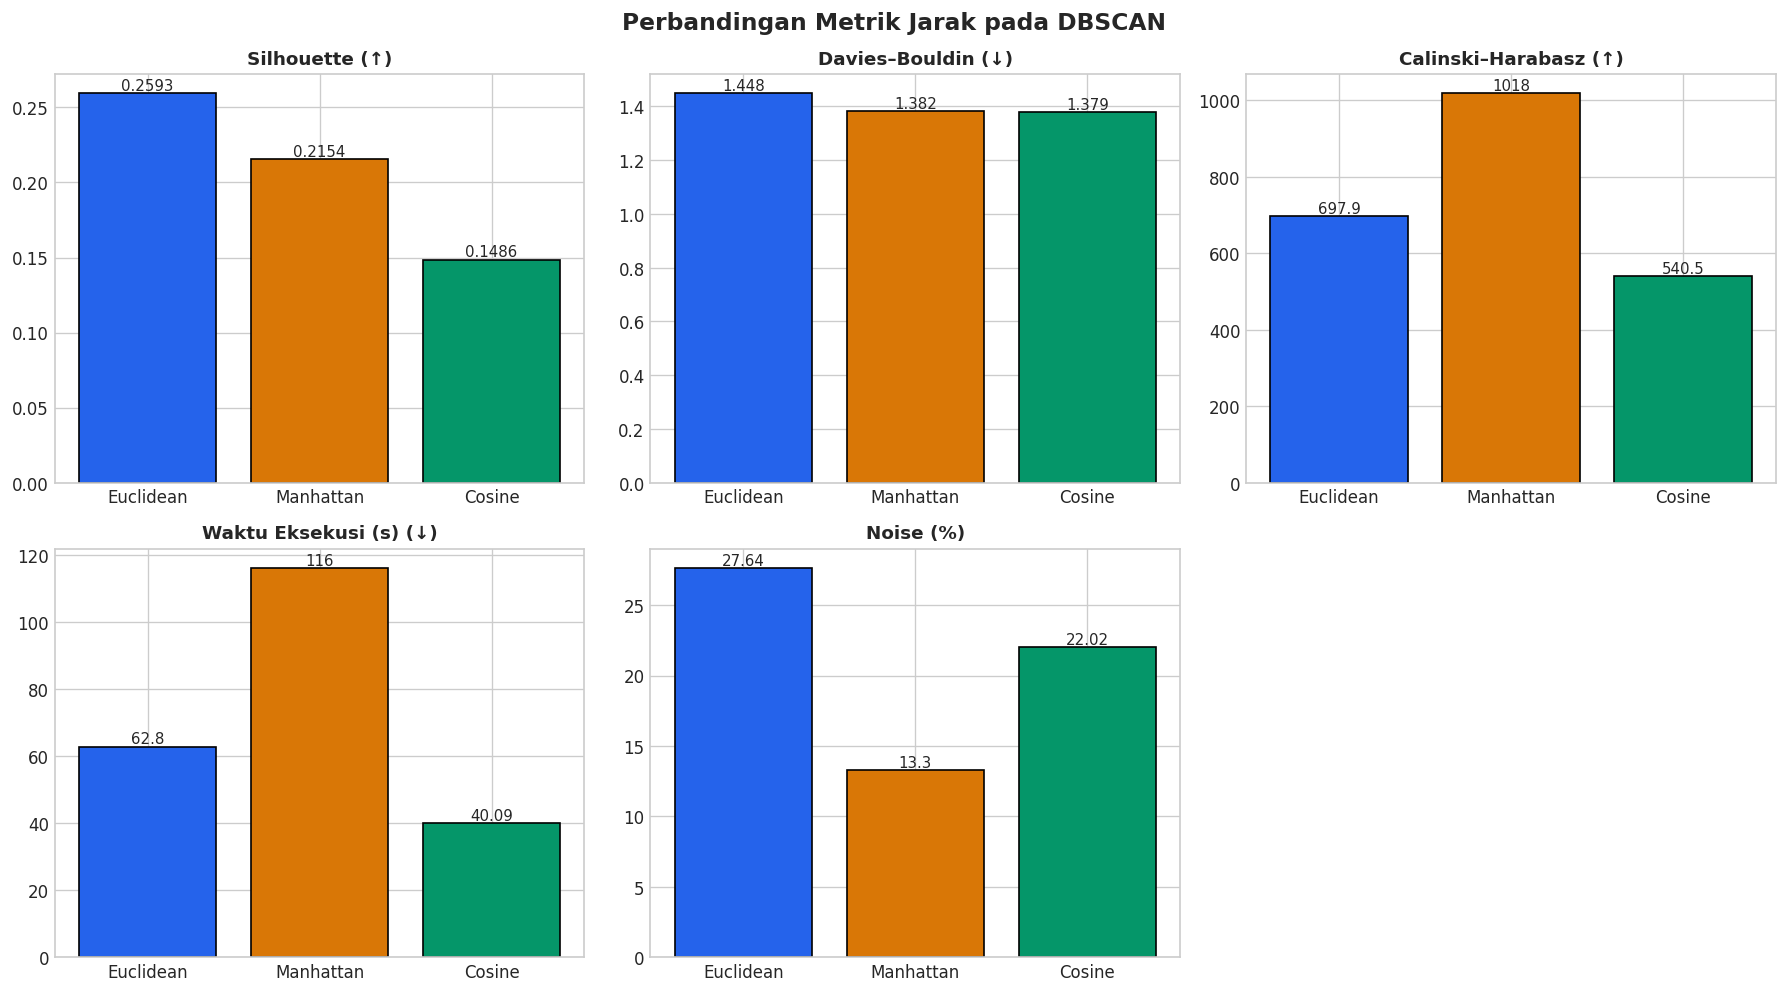

In [ ]:
# grafik perbandingan per algoritma
warna_metrik = {'Euclidean': '#2563EB', 'Manhattan': '#D97706', 'Cosine': '#059669'}

def plot_algoritma(algo):
    sub = tabel_algo[algo]
    panels = [m for m in (metrik_nilai + (['Noise (%)'] if algo == 'DBSCAN' else [])) if sub[m].notna().any()]
    ncols = 3
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, m in zip(axes, panels):
        ax.bar(sub['Metrik Jarak'], sub[m],
               color=[warna_metrik[x] for x in sub['Metrik Jarak']], edgecolor='black')
        for i, v in enumerate(sub[m]):
            ax.text(i, v, f'{v:.4g}', ha='center', va='bottom', fontsize=9)
        ax.set_title(m, fontsize=11, fontweight='bold')
    for ax in axes[len(panels):]:
        ax.axis('off')

    plt.suptitle(f'Perbandingan Metrik Jarak pada {algo}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"perbandingan_{algo.lower().replace('-', '')}.png")
    plt.savefig(path, dpi=300)
    print(f"[SIMPAN] Grafik {algo} disimpan ke: '{path}'")
    plt.show()

plot_algoritma('K-Means')
plot_algoritma('DBSCAN')


In [ ]:
# galeri PCA 2D tiga metrik berdampingan (memakai gambar yang sudah tersimpan)
galeri = {
    'K-Means': [(m, os.path.join(DIR_KMEANS, f'cluster_{m.lower()}.png')) for m in ['Euclidean', 'Manhattan', 'Cosine']],
    'DBSCAN':  [(m, os.path.join(DIR_DBSCAN, f'cluster_dbscan_{m.lower()}.png')) for m in ['Euclidean', 'Manhattan', 'Cosine']],
}

for algo, items in galeri.items():
    fig, axes = plt.subplots(1, 3, figsize=(24, 7))
    for ax, (nama, path) in zip(axes, items):
        if os.path.exists(path):
            ax.imshow(mpimg.imread(path))
            ax.set_title(f'{algo} - {nama}', fontsize=13, fontweight='bold')
        else:
            ax.text(0.5, 0.5, f'Gambar belum ada:\n{os.path.basename(path)}', ha='center', va='center')
        ax.axis('off')
    plt.suptitle(f'Pemetaan Klaster PCA 2D - {algo}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    galeri_path = os.path.join(OUTPUT_DIR, f"galeri_pca_{algo.lower().replace('-', '')}.png")
    plt.savefig(galeri_path, dpi=200, bbox_inches='tight')
    print(f"[SIMPAN] Galeri {algo} disimpan ke: '{galeri_path}'")
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ringkasan pemenang & rekomendasi per algoritma
for algo in ['K-Means', 'DBSCAN']:
    sub = tabel_algo[algo]
    if len(sub) < 2:
        print(f"[LEWAT] {algo}: hasil belum lengkap.")
        continue

    juara = {
        'Silhouette': sub.loc[sub['Silhouette (↑)'].idxmax(), 'Metrik Jarak'],
        'Davies–Bouldin': sub.loc[sub['Davies–Bouldin (↓)'].idxmin(), 'Metrik Jarak'],
        'Calinski–Harabasz': sub.loc[sub['Calinski–Harabasz (↑)'].idxmax(), 'Metrik Jarak'],
        'Waktu eksekusi': sub.loc[sub['Waktu Eksekusi (s) (↓)'].idxmin(), 'Metrik Jarak'],
    }
    if algo == 'DBSCAN':
        juara['Noise paling sedikit'] = sub.loc[sub['Noise (%)'].idxmin(), 'Metrik Jarak']

    print("=" * 85)
    print(f"RINGKASAN & REKOMENDASI - {algo.upper()}")
    print("=" * 85)
    for nama, pemenang in juara.items():
        print(f"  {nama:24s}: {pemenang}")

    suara = Counter([juara['Silhouette'], juara['Davies–Bouldin'], juara['Calinski–Harabasz']])
    (top, n_top), = suara.most_common(1)
    if n_top >= 2:
        print(f"\n  Rekomendasi: {top} Distance unggul di {n_top} dari 3 metrik kualitas klaster.")
    else:
        print("\n  Tidak ada pemenang mutlak (tiap metrik kualitas dimenangkan metrik jarak berbeda); "
              "pertimbangkan Silhouette dan karakteristik data.")
    print()

RINGKASAN & REKOMENDASI - K-MEANS
  Silhouette              : Cosine
  Davies–Bouldin          : Euclidean
  Calinski–Harabasz       : Euclidean
  Waktu eksekusi          : Manhattan

  Rekomendasi: Euclidean Distance unggul di 2 dari 3 metrik kualitas klaster.

RINGKASAN & REKOMENDASI - DBSCAN
  Silhouette              : Euclidean
  Davies–Bouldin          : Cosine
  Calinski–Harabasz       : Manhattan
  Waktu eksekusi          : Cosine
  Noise paling sedikit    : Manhattan

  Tidak ada pemenang mutlak (tiap metrik kualitas dimenangkan metrik jarak berbeda); pertimbangkan Silhouette dan karakteristik data.



# Kesimpulan Kmeans
Pada pengujian algoritma K-Means dengan nilai K=4, performa yang dihasilkan menunjukkan variasi yang jelas. Metrik Euclidean tampil sebagai opsi yang paling efisien secara komputasi dengan waktu eksekusi tercepat, yakni hanya 0,62206 detik. Metrik ini juga berhasil mencatatkan nilai Davies-Bouldin terendah di angka 2.3585 dan Calinski-Harabasz tertinggi sebesar 7218.13. Di sisi lain, jika evaluasi difokuskan pada nilai Silhouette, metrik Cosine memberikan hasil tertinggi sebesar 0.1982, meskipun waktu eksekusinya menjadi yang terlama, yaitu 2,01744 detik. Sementara itu, metrik Manhattan yang disesuaikan menggunakan K=4 agar setara dengan pengujian lainnya menghasilkan performa serta waktu komputasi yang berada di antara metrik Euclidean dan Cosine.

# Kesimpulan DBSCAN

hasil yang diperoleh dari pengujian algoritma DBSCAN dengan parameter MinPts=30 menunjukkan sensitivitas yang sangat tinggi terhadap pemilihan metrik jarak. Penggunaan metrik Euclidean mampu menghasilkan nilai Silhouette tertinggi sebesar 0.2593, namun kelemahannya adalah model ini menciptakan hingga 207 klaster dengan tingkat noise yang sangat tinggi hingga 27,64%. Apabila tujuannya adalah meminimalkan noise dan menyederhanakan pengelompokan, metrik Manhattan menjadi pilihan yang terbaik karena hanya membentuk 3 klaster dengan persentase noise paling rendah di angka 13,30%. Namun, kekurangannya ada pada waktu eksekusi yang melonjak drastis hingga 100,33476 detik. Sebaliknya, metrik Cosine menawarkan waktu proses tercepat untuk kelas DBSCAN (37,86595 detik), tetapi menghasilkan nilai Silhouette terendah sebesar 0.1486 serta membentuk 163 klaster dengan noise sebesar 22,02%.

# Kesimpulan Umum
Secara garis besar, dapat disimpulkan bahwa algoritma K-Means memiliki tingkat efisiensi komputasi yang jauh lebih baik, dengan waktu penyelesaian yang konsisten di bawah 3 detik di semua variasi metrik jarak. Sebaliknya, algoritma DBSCAN tidak hanya memakan sumber daya komputasi yang jauh lebih besar (antara 37 hingga 100 detik), tetapi juga sangat rentan terhadap perubahan metrik jarak, yang berdampak langsung pada drastisnya fluktuasi jumlah klaster dan proporsi noise pada data.


Di luar perbandingan performa teknis tersebut, perlu digarisbawahi juga mengenai tingkat kecocokan karakteristik data dengan algoritma klastering yang digunakan. Nilai evaluasi seperti Silhouette Score yang relatif rendah pada kedua algoritma ini sangat dipengaruhi oleh keberadaan data ordinal di dalam dataset. Data bertipe ordinal pada dasarnya kurang cocok diproses menggunakan algoritma berbasis perhitungan jarak numerik murni seperti K-Means maupun DBSCAN. Ketidaksesuaian antara karakteristik data ordinal dan asumsi matematis dari algoritma tersebut inilah yang pada akhirnya menjadi faktor utama mengapa hasil klastering yang diperoleh menjadi kurang optimal dan titik-titik data tidak dapat dipisahkan menjadi klaster yang padat dan terdefinisi dengan jelas.

In [ ]:
#from google.colab import userdata
# Ambil GitHub Token
#token = userdata.get('GITHUB_TOKEN')

# Clone repository
#%cd /content
#!git clone https://{token}@github.com/FattahulAlim/Machine_Learning_Sem5.git

# Masuk repository
#%cd /content/Machine_Learning_Sem5

# Copy seluruh isi folder kuis1, termasuk semua subfolder
#!cp -r "/content/drive/MyDrive/ml-sem5/kuis1/." kuis1/

# Konfigurasi Git
#!git config user.email "fathalim1512@gmail.com"
#!git config user.name "FattahulAlim"

# Cek perubahan
#!git status

In [ ]:
# Pastikan berada di folder repository
#%cd /content/Machine_Learning_Sem5

# Tambahkan semua file baru ke staging area
#!git add .

# Cek kembali statusnya (sekarang akan muncul "new file: ...")
#!git status

In [ ]:
# Simpan perubahan
#!git commit -m "Menambahkan seluruh file kuis dan dataset Kuis 1"

# Unggah ke GitHub
#!git push origin main